# 四种高光修复方法运行时间基准（统一修复尺寸384×256）

本notebook可独立运行，不读取或执行其他notebook。它直接包含
Partial Convolution与DeepFill v2的模型定义，并统一评估FMM、
Navier–Stokes、Partial Convolution和DeepFill v2。

使用顺序：将`RUN_MODE`依次设置为`check`、`run`和`report`。


In [13]:
import csv
import hashlib
import json
import os
import platform
import random
import re
import subprocess
import sys
import tempfile
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from IPython.display import display
from PIL import Image
from torchvision import transforms


# ==================== 路径与运行模式 ====================
NOTEBOOK_DIR = Path.cwd().resolve()
DATA_ROOT = Path("/home/wujieyu/jupyterlab/tensorflow/paper1/Data")
IMAGE_DIR = DATA_ROOT / "Train" / "img"
PCONV_WEIGHT = NOTEBOOK_DIR / "pconv_places2.pth"
DEEPFILL_WEIGHT = NOTEBOOK_DIR / "Deepfillv2-states_tf_places2.pth"

OUTPUT_DIR = NOTEBOOK_DIR / "outputs_highlight_removal_runtime"
RAW_DIR = OUTPUT_DIR / "raw_results"
FIGURE_DIR = OUTPUT_DIR / "figures"
TEMP_IO_DIR = OUTPUT_DIR / "temporary_file_io"
for directory in (OUTPUT_DIR, RAW_DIR, FIGURE_DIR, TEMP_IO_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# 依次运行 check -> run -> report。
RUN_MODE = "report"
if RUN_MODE not in {"check", "run", "report"}:
    raise ValueError('RUN_MODE只能是"check"、"run"或"report"。')


# ==================== 固定实验协议 ====================
METHODS = ["fmm", "ns", "partial_conv", "deepfill_v2"]
METHOD_LABELS = {
    "fmm": "FMM/TELEA",
    "ns": "NS/Navier-Stokes",
    "partial_conv": "Partial Convolution",
    "deepfill_v2": "DeepFill v2",
}
PROTOCOLS = {
    "fair_cpu_common": "all_cpu",
    "native_device_pipeline": "native",
}
PROTOCOL_LABELS = {
    "fair_cpu_common": "Unified CPU (8 threads)",
    "native_device_pipeline": "Native device",
}

RESTORE_WIDTH, RESTORE_HEIGHT = 384, 256
OUTPUT_WIDTH, OUTPUT_HEIGHT = 384, 288
RESTORE_SIZE = (RESTORE_WIDTH, RESTORE_HEIGHT)
OUTPUT_SIZE = (OUTPUT_WIDTH, OUTPUT_HEIGHT)

PERCENTILE = 99.5
INPAINT_RADIUS = 10
CPU_THREADS = 8
BATCH_SIZE = 1
WARMUP_IMAGES = 30
RUNS = 3
BASE_SEED = 20260818
MAX_IMAGES = None
SCHEMA_VERSION = 12

assert RESTORE_SIZE == (384, 256)
assert OUTPUT_SIZE == (384, 288)
assert PERCENTILE == 99.5
assert CPU_THREADS == 8 and BATCH_SIZE == 1 and RUNS == 3

print("运行模式：", RUN_MODE)
print("统一修复尺寸：", RESTORE_SIZE)
print("最终评价尺寸：", OUTPUT_SIZE)
print("基础随机种子：", BASE_SEED)
print("统一输出编码：PNG")
print("输出目录：", OUTPUT_DIR)


运行模式： report
统一修复尺寸： (384, 256)
最终评价尺寸： (384, 288)
基础随机种子： 20260818
统一输出编码：PNG
输出目录： /home/wujieyu/jupyterlab/tensorflow/supplement/paper1/time/outputs_highlight_removal_runtime


## Partial Convolution模型定义

以下网络定义直接复制自原PConv notebook，仅复用本notebook顶部的公共导入。


In [14]:
# =========================================================
# ImageNet normalization
# 推理时必须与训练保持一致
# =========================================================
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# partial-conv:
# https://github.com/naoto0804/pytorch-inpainting-with-partial-conv
# weight:
# https://github.com/naoto0804/pytorch-inpainting-with-partial-conv/releases/tag/v0.0.0

# =========================================================
# 网络初始化
# =========================================================
def weights_init(init_type='gaussian'):
    def init_fun(m):
        classname = m.__class__.__name__
        if (classname.find('Conv') == 0 or classname.find('Linear') == 0) and hasattr(m, 'weight'):
            if init_type == 'gaussian':
                nn.init.normal_(m.weight, 0.0, 0.02)
            elif init_type == 'kaiming':
                nn.init.kaiming_normal_(m.weight, a=0, mode='fan_in')
            if hasattr(m, 'bias') and m.bias is not None:
                nn.init.constant_(m.bias, 0.0)
    return init_fun


# =========================================================
# Partial Convolution
# =========================================================
class PartialConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1,
                 padding=0, dilation=1, groups=1, bias=True):
        super().__init__()
        self.input_conv = nn.Conv2d(
            in_channels, out_channels, kernel_size,
            stride, padding, dilation, groups, bias
        )
        self.mask_conv = nn.Conv2d(
            in_channels, out_channels, kernel_size,
            stride, padding, dilation, groups, False
        )

        self.input_conv.apply(weights_init('kaiming'))
        torch.nn.init.constant_(self.mask_conv.weight, 1.0)

        for param in self.mask_conv.parameters():
            param.requires_grad = False

    def forward(self, input, mask):
        output = self.input_conv(input * mask)

        if self.input_conv.bias is not None:
            output_bias = self.input_conv.bias.view(1, -1, 1, 1).expand_as(output)
        else:
            output_bias = torch.zeros_like(output)

        with torch.no_grad():
            output_mask = self.mask_conv(mask)

        no_update_holes = output_mask == 0
        mask_sum = output_mask.masked_fill(no_update_holes, 1.0)

        output_pre = (output - output_bias) / mask_sum + output_bias
        output = output_pre.masked_fill(no_update_holes, 0.0)

        new_mask = torch.ones_like(output)
        new_mask = new_mask.masked_fill(no_update_holes, 0.0)

        return output, new_mask


# =========================================================
# 编码/解码模块
# =========================================================
class PCBActiv(nn.Module):
    def __init__(self, in_ch, out_ch, bn=True, sample='none-3', activ='relu', conv_bias=False):
        super().__init__()

        if sample == 'down-5':
            self.conv = PartialConv(in_ch, out_ch, 5, 2, 2, bias=conv_bias)
        elif sample == 'down-7':
            self.conv = PartialConv(in_ch, out_ch, 7, 2, 3, bias=conv_bias)
        elif sample == 'down-3':
            self.conv = PartialConv(in_ch, out_ch, 3, 2, 1, bias=conv_bias)
        else:
            self.conv = PartialConv(in_ch, out_ch, 3, 1, 1, bias=conv_bias)

        if bn:
            self.bn = nn.BatchNorm2d(out_ch)

        if activ == 'relu':
            self.activation = nn.ReLU()
        elif activ == 'leaky':
            self.activation = nn.LeakyReLU(negative_slope=0.2)

    def forward(self, input, input_mask):
        h, h_mask = self.conv(input, input_mask)

        if hasattr(self, 'bn'):
            h = self.bn(h)

        if hasattr(self, 'activation'):
            h = self.activation(h)

        return h, h_mask


# =========================================================
# PConv U-Net
# =========================================================
class PConvUNet(nn.Module):
    def __init__(self, layer_size=7, input_channels=3, upsampling_mode='nearest'):
        super().__init__()

        self.freeze_enc_bn = False
        self.upsampling_mode = upsampling_mode
        self.layer_size = layer_size

        self.enc_1 = PCBActiv(input_channels, 64, bn=False, sample='down-7')
        self.enc_2 = PCBActiv(64, 128, sample='down-5')
        self.enc_3 = PCBActiv(128, 256, sample='down-5')
        self.enc_4 = PCBActiv(256, 512, sample='down-3')

        for i in range(4, self.layer_size):
            setattr(self, f'enc_{i + 1}', PCBActiv(512, 512, sample='down-3'))

        for i in range(4, self.layer_size):
            setattr(self, f'dec_{i + 1}', PCBActiv(512 + 512, 512, activ='leaky'))

        self.dec_4 = PCBActiv(512 + 256, 256, activ='leaky')
        self.dec_3 = PCBActiv(256 + 128, 128, activ='leaky')
        self.dec_2 = PCBActiv(128 + 64, 64, activ='leaky')
        self.dec_1 = PCBActiv(64 + input_channels, input_channels, bn=False, activ=None, conv_bias=True)

    def forward(self, input, input_mask):
        h_dict, h_mask_dict = {}, {}
        h_dict['h_0'], h_mask_dict['h_0'] = input, input_mask
        h_key_prev = 'h_0'

        for i in range(1, self.layer_size + 1):
            l_key = f'enc_{i}'
            h_key = f'h_{i}'
            h_dict[h_key], h_mask_dict[h_key] = getattr(self, l_key)(
                h_dict[h_key_prev], h_mask_dict[h_key_prev]
            )
            h_key_prev = h_key

        h_key = f'h_{self.layer_size}'
        h, h_mask = h_dict[h_key], h_mask_dict[h_key]

        for i in range(self.layer_size, 0, -1):
            enc_h_key = f'h_{i - 1}'
            dec_l_key = f'dec_{i}'

            h = F.interpolate(h, scale_factor=2, mode=self.upsampling_mode)
            h_mask = F.interpolate(h_mask, scale_factor=2, mode='nearest')

            h = torch.cat([h, h_dict[enc_h_key]], dim=1)
            h_mask = torch.cat([h_mask, h_mask_dict[enc_h_key]], dim=1)

            h, h_mask = getattr(self, dec_l_key)(h, h_mask)

        return h, h_mask


## DeepFill v2模型定义

以下网络定义直接复制自原DeepFill v2 notebook，仅复用本notebook顶部的公共导入。


In [15]:
# https://github.com/nipponjo/deepfillv2-pytorch/tree/master
# =========================================================
# 基础工具
# =========================================================
def _init_conv_layer(conv, activation, mode='fan_out'):
    if isinstance(activation, nn.LeakyReLU):
        torch.nn.init.kaiming_uniform_(
            conv.weight,
            a=activation.negative_slope,
            nonlinearity='leaky_relu',
            mode=mode
        )
    elif isinstance(activation, (nn.ReLU, nn.ELU)):
        torch.nn.init.kaiming_uniform_(
            conv.weight,
            nonlinearity='relu',
            mode=mode
        )
    if conv.bias is not None:
        torch.nn.init.zeros_(conv.bias)


def output_to_image(out):
    out = (out[0].cpu().permute(1, 2, 0) + 1.) * 127.5
    out = out.to(torch.uint8).numpy()
    return out


def same_padding(images, ksizes, strides, rates):
    """
    TensorFlow SAME padding
    """
    in_height, in_width = images.shape[2:]
    out_height = -(in_height // -strides[0])  # ceil
    out_width = -(in_width // -strides[1])

    filter_height = (ksizes[0] - 1) * rates[0] + 1
    filter_width = (ksizes[1] - 1) * rates[1] + 1

    pad_along_height = max((out_height - 1) * strides[0] + filter_height - in_height, 0)
    pad_along_width = max((out_width - 1) * strides[1] + filter_width - in_width, 0)

    pad_top = pad_along_height // 2
    pad_bottom = pad_along_height - pad_top
    pad_left = pad_along_width // 2
    pad_right = pad_along_width - pad_left

    paddings = (pad_left, pad_right, pad_top, pad_bottom)
    padded_images = torch.nn.ZeroPad2d(paddings)(images)
    return padded_images


def downsampling_nn_tf(images, n=2):
    """
    TensorFlow 风格最近邻下采样
    """
    in_height, in_width = images.shape[2:]
    out_height, out_width = in_height // n, in_width // n
    height_inds = torch.linspace(
        0, in_height - 1, steps=out_height, device=images.device
    ).add_(0.5).floor_().long()
    width_inds = torch.linspace(
        0, in_width - 1, steps=out_width, device=images.device
    ).add_(0.5).floor_().long()
    return images[:, :, height_inds][..., width_inds]


def extract_image_patches(images, ksizes, strides, rates, padding='same'):
    """
    Extract sliding local blocks
    """
    if padding == 'same':
        images = same_padding(images, ksizes, strides, rates)
        padding = 0

    unfold = torch.nn.Unfold(
        kernel_size=ksizes,
        stride=strides,
        padding=padding,
        dilation=rates
    )
    patches = unfold(images)
    return patches


# =========================================================
# Flow 可视化相关（contextual attention 会用到）
# =========================================================
def flow_to_image(flow):
    out = []
    maxu = -999.
    maxv = -999.
    minu = 999.
    minv = 999.
    maxrad = -1
    for i in range(flow.shape[0]):
        u = flow[i, :, :, 0]
        v = flow[i, :, :, 1]
        idxunknow = (abs(u) > 1e7) | (abs(v) > 1e7)
        u[idxunknow] = 0
        v[idxunknow] = 0
        maxu = max(maxu, np.max(u))
        minu = min(minu, np.min(u))
        maxv = max(maxv, np.max(v))
        minv = min(minv, np.min(v))
        rad = np.sqrt(u ** 2 + v ** 2)
        maxrad = max(maxrad, np.max(rad))
        u = u / (maxrad + np.finfo(float).eps)
        v = v / (maxrad + np.finfo(float).eps)
        img = compute_color(u, v)
        out.append(img)
    return np.float32(np.uint8(out))


def compute_color(u, v):
    h, w = u.shape
    img = np.zeros([h, w, 3])
    nanIdx = np.isnan(u) | np.isnan(v)
    u[nanIdx] = 0
    v[nanIdx] = 0
    colorwheel = make_color_wheel()
    ncols = np.size(colorwheel, 0)
    rad = np.sqrt(u ** 2 + v ** 2)
    a = np.arctan2(-v, -u) / np.pi
    fk = (a + 1) / 2 * (ncols - 1) + 1
    k0 = np.floor(fk).astype(int)
    k1 = k0 + 1
    k1[k1 == ncols + 1] = 1
    f = fk - k0
    for i in range(np.size(colorwheel, 1)):
        tmp = colorwheel[:, i]
        col0 = tmp[k0 - 1] / 255
        col1 = tmp[k1 - 1] / 255
        col = (1 - f) * col0 + f * col1
        idx = rad <= 1
        col[idx] = 1 - rad[idx] * (1 - col[idx])
        notidx = np.logical_not(idx)
        col[notidx] *= 0.75
        img[:, :, i] = np.uint8(np.floor(255 * col * (1 - nanIdx)))
    return img


def make_color_wheel():
    RY, YG, GC, CB, BM, MR = (15, 6, 4, 11, 13, 6)
    ncols = RY + YG + GC + CB + BM + MR
    colorwheel = np.zeros([ncols, 3])
    col = 0

    colorwheel[0:RY, 0] = 255
    colorwheel[0:RY, 1] = np.transpose(np.floor(255 * np.arange(0, RY) / RY))
    col += RY

    colorwheel[col:col + YG, 0] = 255 - np.transpose(np.floor(255 * np.arange(0, YG) / YG))
    colorwheel[col:col + YG, 1] = 255
    col += YG

    colorwheel[col:col + GC, 1] = 255
    colorwheel[col:col + GC, 2] = np.transpose(np.floor(255 * np.arange(0, GC) / GC))
    col += GC

    colorwheel[col:col + CB, 1] = 255 - np.transpose(np.floor(255 * np.arange(0, CB) / CB))
    colorwheel[col:col + CB, 2] = 255
    col += CB

    colorwheel[col:col + BM, 2] = 255
    colorwheel[col:col + BM, 0] = np.transpose(np.floor(255 * np.arange(0, BM) / BM))
    col += BM

    colorwheel[col:col + MR, 2] = 255 - np.transpose(np.floor(255 * np.arange(0, MR) / MR))
    colorwheel[col:col + MR, 0] = 255
    return colorwheel


# =========================================================
# Gated Convolution
# =========================================================
class GConv(nn.Module):
    """
    Gated Convolution (TensorFlow-style SAME padding)
    """

    def __init__(self, cnum_in, cnum_out, ksize, stride=1, rate=1,
                 padding='same', activation=nn.ELU()):
        super().__init__()

        self.activation = activation
        self.cnum_out = cnum_out
        num_conv_out = cnum_out if self.cnum_out == 3 or self.activation is None else 2 * cnum_out

        self.conv = nn.Conv2d(
            cnum_in,
            num_conv_out,
            kernel_size=ksize,
            stride=stride,
            padding=0,
            dilation=rate
        )
        _init_conv_layer(self.conv, activation=self.activation)

        self.ksize = ksize
        self.stride = stride
        self.rate = rate
        self.padding = padding

    def forward(self, x):
        x = same_padding(
            x,
            [self.ksize, self.ksize],
            [self.stride, self.stride],
            [self.rate, self.rate]
        )

        x = self.conv(x)

        if self.cnum_out == 3 or self.activation is None:
            return x

        x, y = torch.split(x, self.cnum_out, dim=1)
        x = self.activation(x)
        y = torch.sigmoid(y)
        x = x * y
        return x


class GDeConv(nn.Module):
    """
    Upsampling followed by GConv
    """
    def __init__(self, cnum_in, cnum_out, padding=1):
        super().__init__()
        self.conv = GConv(cnum_in, cnum_out, 3, 1, padding=padding)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest', recompute_scale_factor=False)
        x = self.conv(x)
        return x


# =========================================================
# Contextual Attention
# =========================================================
class ContextualAttention(nn.Module):
    def __init__(self, ksize=3, stride=1, rate=1, fuse_k=3,
                 softmax_scale=10., n_down=2, fuse=True,
                 return_flow=False, device_ids=None):
        super().__init__()
        self.ksize = ksize
        self.stride = stride
        self.rate = rate
        self.fuse_k = fuse_k
        self.softmax_scale = softmax_scale
        self.fuse = fuse
        self.device_ids = device_ids
        self.n_down = n_down
        self.return_flow = return_flow

    def forward(self, f, b, mask=None):
        device = f.device
        raw_int_fs, raw_int_bs = list(f.size()), list(b.size())

        kernel = 2 * self.rate
        raw_w = extract_image_patches(
            b,
            ksizes=[kernel, kernel],
            strides=[self.rate * self.stride, self.rate * self.stride],
            rates=[1, 1],
            padding='same'
        )
        raw_w = raw_w.view(raw_int_bs[0], raw_int_bs[1], kernel, kernel, -1)
        raw_w = raw_w.permute(0, 4, 1, 2, 3)
        raw_w_groups = torch.split(raw_w, 1, dim=0)

        f = downsampling_nn_tf(f, n=self.rate)
        b = downsampling_nn_tf(b, n=self.rate)
        int_fs, int_bs = list(f.size()), list(b.size())

        f_groups = torch.split(f, 1, dim=0)

        w = extract_image_patches(
            b,
            ksizes=[self.ksize, self.ksize],
            strides=[self.stride, self.stride],
            rates=[1, 1],
            padding='same'
        )
        w = w.view(int_bs[0], int_bs[1], self.ksize, self.ksize, -1)
        w = w.permute(0, 4, 1, 2, 3)
        w_groups = torch.split(w, 1, dim=0)

        if mask is None:
            mask = torch.zeros([int_bs[0], 1, int_bs[2], int_bs[3]], device=device)
        else:
            mask = downsampling_nn_tf(mask, n=(2 ** self.n_down) * self.rate)

        int_ms = list(mask.size())
        m = extract_image_patches(
            mask,
            ksizes=[self.ksize, self.ksize],
            strides=[self.stride, self.stride],
            rates=[1, 1],
            padding='same'
        )
        m = m.view(int_ms[0], int_ms[1], self.ksize, self.ksize, -1)
        m = m.permute(0, 4, 1, 2, 3)
        m = m[0]

        mm = (torch.mean(m, axis=[1, 2, 3], keepdim=True) == 0.).to(torch.float32)
        mm = mm.permute(1, 0, 2, 3)

        y = []
        offsets = []
        k = self.fuse_k
        scale = self.softmax_scale
        fuse_weight = torch.eye(k, device=device).view(1, 1, k, k)

        for xi, wi, raw_wi in zip(f_groups, w_groups, raw_w_groups):
            wi = wi[0]
            max_wi = torch.sqrt(torch.sum(torch.pow(wi, 2), dim=[1, 2, 3], keepdim=True)).clamp_min(1e-4)
            wi_normed = wi / max_wi

            xi = same_padding(xi, [self.ksize, self.ksize], [1, 1], [1, 1])
            yi = F.conv2d(xi, wi_normed, stride=1)

            if self.fuse:
                yi = yi.view(1, 1, int_bs[2] * int_bs[3], int_fs[2] * int_fs[3])
                yi = same_padding(yi, [k, k], [1, 1], [1, 1])
                yi = F.conv2d(yi, fuse_weight, stride=1)
                yi = yi.contiguous().view(1, int_bs[2], int_bs[3], int_fs[2], int_fs[3])
                yi = yi.permute(0, 2, 1, 4, 3).contiguous()

                yi = yi.view(1, 1, int_bs[2] * int_bs[3], int_fs[2] * int_fs[3])
                yi = same_padding(yi, [k, k], [1, 1], [1, 1])
                yi = F.conv2d(yi, fuse_weight, stride=1)
                yi = yi.contiguous().view(1, int_bs[3], int_bs[2], int_fs[3], int_fs[2])
                yi = yi.permute(0, 2, 1, 4, 3).contiguous()

            yi = yi.view(1, int_bs[2] * int_bs[3], int_fs[2], int_fs[3])

            yi = yi * mm
            yi = F.softmax(yi * scale, dim=1)
            yi = yi * mm

            if self.return_flow:
                offset = torch.argmax(yi, dim=1, keepdim=True)

                if int_bs != int_fs:
                    times = (int_fs[2] * int_fs[3]) / (int_bs[2] * int_bs[3])
                    offset = ((offset + 1) * times - 1).to(torch.int64)

                offset = torch.cat([
                    torch.div(offset, int_fs[3], rounding_mode='trunc'),
                    offset % int_fs[3]
                ], dim=1)
                offsets.append(offset)

            wi_center = raw_wi[0]
            yi = F.conv_transpose2d(yi, wi_center, stride=self.rate, padding=1) / 4.
            y.append(yi)

        y = torch.cat(y, dim=0)
        y = y.contiguous().view(raw_int_fs)

        if not self.return_flow:
            return y, None

        offsets = torch.cat(offsets, dim=0)
        offsets = offsets.view(int_fs[0], 2, *int_fs[2:])

        h_add = torch.arange(int_fs[2], device=device).view([1, 1, int_fs[2], 1]).expand(int_fs[0], -1, -1, int_fs[3])
        w_add = torch.arange(int_fs[3], device=device).view([1, 1, 1, int_fs[3]]).expand(int_fs[0], -1, int_fs[2], -1)
        offsets = offsets - torch.cat([h_add, w_add], dim=1)

        flow = torch.from_numpy(flow_to_image(offsets.permute(0, 2, 3, 1).detach().cpu().numpy())) / 255.
        flow = flow.permute(0, 3, 1, 2)

        if self.rate != 1:
            flow = F.interpolate(flow, scale_factor=self.rate, mode='bilinear', align_corners=True)

        return y, flow


# =========================================================
# DeepFill v2 Generator (networks_tf style)
# =========================================================
class Generator(nn.Module):
    def __init__(self, cnum_in=5, cnum=48, return_flow=False, checkpoint=None):
        super().__init__()

        # ---------------- Stage 1 ----------------
        self.conv1 = GConv(cnum_in, cnum // 2, 5, 1, padding=2)
        self.conv2_downsample = GConv(cnum // 2, cnum, 3, 2)
        self.conv3 = GConv(cnum, cnum, 3, 1)
        self.conv4_downsample = GConv(cnum, 2 * cnum, 3, 2)
        self.conv5 = GConv(2 * cnum, 2 * cnum, 3, 1)

        self.conv6 = GConv(2 * cnum, 2 * cnum, 3, 1)
        self.conv7_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=2, padding=2)
        self.conv8_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=4, padding=4)
        self.conv9_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=8, padding=8)
        self.conv10_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=16, padding=16)
        self.conv11 = GConv(2 * cnum, 2 * cnum, 3, 1)
        self.conv12 = GConv(2 * cnum, 2 * cnum, 3, 1)

        self.conv13_upsample = GDeConv(2 * cnum, cnum)
        self.conv14 = GConv(cnum, cnum, 3, 1)
        self.conv15_upsample = GDeConv(cnum, cnum // 2)
        self.conv16 = GConv(cnum // 2, cnum // 4, 3, 1)
        self.conv17 = GConv(cnum // 4, 3, 3, 1, activation=None)
        self.tanh = nn.Tanh()

        # ---------------- Stage 2 conv branch ----------------
        self.xconv1 = GConv(3, cnum // 2, 5, 1, padding=2)
        self.xconv2_downsample = GConv(cnum // 2, cnum // 2, 3, 2)
        self.xconv3 = GConv(cnum // 2, cnum, 3, 1)
        self.xconv4_downsample = GConv(cnum, cnum, 3, 2)
        self.xconv5 = GConv(cnum, 2 * cnum, 3, 1)

        self.xconv6 = GConv(2 * cnum, 2 * cnum, 3, 1)
        self.xconv7_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=2, padding=2)
        self.xconv8_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=4, padding=4)
        self.xconv9_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=8, padding=8)
        self.xconv10_atrous = GConv(2 * cnum, 2 * cnum, 3, rate=16, padding=16)

        # ---------------- Stage 2 attention branch ----------------
        self.pmconv1 = GConv(3, cnum // 2, 5, 1, padding=2)
        self.pmconv2_downsample = GConv(cnum // 2, cnum // 2, 3, 2)
        self.pmconv3 = GConv(cnum // 2, cnum, 3, 1)
        self.pmconv4_downsample = GConv(cnum, 2 * cnum, 3, 2)
        self.pmconv5 = GConv(2 * cnum, 2 * cnum, 3, 1)

        self.pmconv6 = GConv(2 * cnum, 2 * cnum, 3, 1, activation=nn.ReLU())
        self.contextual_attention = ContextualAttention(
            ksize=3,
            stride=1,
            rate=2,
            fuse_k=3,
            softmax_scale=10,
            fuse=False,
            device_ids=None,
            n_down=2,
            return_flow=return_flow
        )
        self.pmconv9 = GConv(2 * cnum, 2 * cnum, 3, 1)
        self.pmconv10 = GConv(2 * cnum, 2 * cnum, 3, 1)

        self.allconv11 = GConv(4 * cnum, 2 * cnum, 3, 1)
        self.allconv12 = GConv(2 * cnum, 2 * cnum, 3, 1)
        self.allconv13_upsample = GDeConv(2 * cnum, cnum)
        self.allconv14 = GConv(cnum, cnum, 3, 1)
        self.allconv15_upsample = GDeConv(cnum, cnum // 2)
        self.allconv16 = GConv(cnum // 2, cnum // 4, 3, 1)
        self.allconv17 = GConv(cnum // 4, 3, 3, 1, activation=None)

        self.return_flow = return_flow

        if checkpoint is not None:
            generator_state_dict = torch.load(checkpoint, map_location="cpu")['G']
            self.load_state_dict(generator_state_dict, strict=True)

        self.eval()

    def forward(self, x, mask):
        xin = x

        # stage 1
        x = self.conv1(x)
        x = self.conv2_downsample(x)
        x = self.conv3(x)
        x = self.conv4_downsample(x)
        x = self.conv5(x)

        x = self.conv6(x)
        x = self.conv7_atrous(x)
        x = self.conv8_atrous(x)
        x = self.conv9_atrous(x)
        x = self.conv10_atrous(x)
        x = self.conv11(x)
        x = self.conv12(x)

        x = self.conv13_upsample(x)
        x = self.conv14(x)
        x = self.conv15_upsample(x)
        x = self.conv16(x)

        x = self.conv17(x)
        x = self.tanh(x)
        x_stage1 = x

        # stage 2
        x = x * mask + xin[:, 0:3, :, :] * (1. - mask)

        # conv branch
        xnow = x
        x = self.xconv1(xnow)
        x = self.xconv2_downsample(x)
        x = self.xconv3(x)
        x = self.xconv4_downsample(x)
        x = self.xconv5(x)

        x = self.xconv6(x)
        x = self.xconv7_atrous(x)
        x = self.xconv8_atrous(x)
        x = self.xconv9_atrous(x)
        x = self.xconv10_atrous(x)
        x_hallu = x

        # attention branch
        x = self.pmconv1(xnow)
        x = self.pmconv2_downsample(x)
        x = self.pmconv3(x)
        x = self.pmconv4_downsample(x)
        x = self.pmconv5(x)

        x = self.pmconv6(x)
        x, offset_flow = self.contextual_attention(x, x, mask)
        x = self.pmconv9(x)
        x = self.pmconv10(x)
        pm = x

        x = torch.cat([x_hallu, pm], dim=1)

        x = self.allconv11(x)
        x = self.allconv12(x)
        x = self.allconv13_upsample(x)
        x = self.allconv14(x)
        x = self.allconv15_upsample(x)
        x = self.allconv16(x)

        x = self.allconv17(x)
        x = self.tanh(x)
        x_stage2 = x

        if self.return_flow:
            return x_stage1, x_stage2, offset_flow

        return x_stage1, x_stage2

## 统一适配与计时

四种方法统一在384×256图像和同一个99.5% mask上修复，核心输出仍为384×256，最后统一缩放至384×288。FMM/NS仅取消原0.6倍缩放，其修复算子和半径不变。四种方法统一使用无损PNG输出；每次运行固定Python、NumPy、PyTorch、CUDA及Python哈希种子。


In [16]:
# ==================== 基础工具 ====================
MODEL_SOURCE_SHA256 = {'partial_conv': '7f04cb08efdc7cb92500430312ba84e5b375cef5420aa96991dfc0dc5f52dcaa', 'deepfill_v2': '25361fd3751cb92f98f0977427dc25013abc734569178d79e4c57fc0b0d7abfe'}
ADAPTER_VERSION = "unified-restoration-384x256-png-seeded-supplementary-table"


def natural_key(path):
    """按文件名中的数字自然排序，例如2.jpg排在10.jpg之前。"""
    return [
        int(part) if part.isdigit() else part.lower()
        for part in re.split(r"(\d+)", Path(path).name)
    ]


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_json(path, payload):
    """先写临时文件再替换，防止中断后留下不完整结果。"""
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    temporary.replace(path)


def cpu_model_name():
    """优先读取Linux CPU完整型号，避免platform.processor()为空。"""
    cpuinfo = Path("/proc/cpuinfo")
    if cpuinfo.is_file():
        for line in cpuinfo.read_text(encoding="utf-8", errors="ignore").splitlines():
            if line.lower().startswith("model name") and ":" in line:
                return line.split(":", 1)[1].strip()
    try:
        completed = subprocess.run(
            ["lscpu"], text=True, capture_output=True, check=False
        )
        for line in completed.stdout.splitlines():
            if line.lower().startswith("model name") and ":" in line:
                return line.split(":", 1)[1].strip()
    except FileNotFoundError:
        pass
    return platform.processor() or platform.machine() or "Unknown CPU"


def physical_cpu_count():
    try:
        import psutil
        count = psutil.cpu_count(logical=False)
        if count:
            return int(count)
    except Exception:
        pass
    try:
        completed = subprocess.run(
            ["lscpu", "-p=SOCKET,CORE"],
            text=True,
            capture_output=True,
            check=False,
        )
        cores = {
            tuple(line.split(",")[:2])
            for line in completed.stdout.splitlines()
            if line and not line.startswith("#")
        }
        return len(cores) or None
    except FileNotFoundError:
        return None


def total_memory_gib():
    try:
        import psutil
        return float(psutil.virtual_memory().total / (1024 ** 3))
    except Exception:
        meminfo = Path("/proc/meminfo")
        if meminfo.is_file():
            for line in meminfo.read_text(encoding="utf-8", errors="ignore").splitlines():
                if line.startswith("MemTotal:"):
                    return float(line.split()[1]) / (1024 ** 2)
    return None


def collect_environment():
    environment = {
        "cpu_model": cpu_model_name(),
        "physical_cpu_count": physical_cpu_count(),
        "logical_cpu_count": os.cpu_count(),
        "memory_total_gib": total_memory_gib(),
        "python": platform.python_version(),
        "platform": platform.platform(),
        "numpy": np.__version__,
        "opencv": cv2.__version__,
        "torch": str(torch.__version__),
        "torchvision": str(torchvision.__version__),
        "cuda": str(torch.version.cuda),
        "cudnn": str(torch.backends.cudnn.version()),
        "cpu_threads": CPU_THREADS,
        "base_seed": BASE_SEED,
        "output_encoding": "PNG",
    }
    try:
        query = [
            "nvidia-smi",
            "--query-gpu=index,name,memory.total,driver_version",
            "--format=csv,noheader,nounits",
        ]
        completed = subprocess.run(query, text=True, capture_output=True, check=False)
        environment["nvidia_gpus"] = [
            line.strip() for line in completed.stdout.splitlines() if line.strip()
        ]
    except FileNotFoundError:
        environment["nvidia_gpus"] = []
    return environment


def set_random_seed(seed):
    """固定Python、NumPy、PyTorch和CUDA随机种子。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def configure_worker_threads():
    """每个子进程固定使用8个CPU线程。"""
    for name in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS",
                 "NUMEXPR_NUM_THREADS"):
        os.environ[name] = str(CPU_THREADS)
    cv2.setNumThreads(CPU_THREADS)
    torch.set_num_threads(CPU_THREADS)
    try:
        torch.set_num_interop_threads(1)
    except RuntimeError:
        pass


def synchronize(device):
    if device is not None and device.type == "cuda":
        torch.cuda.synchronize(device)


# ==================== 模型加载 ====================
def load_partial_conv(weight_path, device):
    """直接采用原PConv notebook的权重加载过程。"""
    model = PConvUNet().to(device)

    ckpt = torch.load(weight_path, map_location=device)

    if "model" in ckpt:
        state_dict = ckpt["model"]
    else:
        state_dict = ckpt

    model.load_state_dict(state_dict, strict=True)
    model.eval()
    return model


def load_deepfill(weight_path, device):
    """直接采用原DeepFill v2 notebook的权重加载过程。"""
    checkpoint = torch.load(weight_path, map_location=device)

    if "G" not in checkpoint:
        raise KeyError("DeepFill v2权重中缺少生成器键'G'。")

    generator_state_dict = checkpoint["G"]

    model = Generator(cnum_in=5, cnum=48, return_flow=False).to(device)
    model.load_state_dict(generator_state_dict, strict=True)
    model.eval()
    return model


# ==================== 方法输入与高光检测 ====================


def prepare_restoration_input(image_bgr):
    """将已解码图像统一缩放至384x256，供四种方法共同修复。"""
    if image_bgr is None or image_bgr.ndim != 3:
        raise ValueError("需要已解码的BGR彩色图像。")
    return cv2.resize(image_bgr, RESTORE_SIZE, interpolation=cv2.INTER_LINEAR)


def create_highlight_mask(img_bgr):
    """原99.5%检测代码；额外返回阈值供CSV记录。"""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    threshold = np.percentile(gray, PERCENTILE)
    _, mask = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)

    return mask, float(threshold)


# ==================== 四种核心修复方法 ====================
def restore_classical(image, highlight_mask, method):
    """在统一384x256尺寸上执行原FMM或NS修复算子。"""
    flag = cv2.INPAINT_TELEA if method == "fmm" else cv2.INPAINT_NS

    started = time.perf_counter()
    dst = cv2.inpaint(image, highlight_mask, INPAINT_RADIUS, flag)
    core_ms = (time.perf_counter() - started) * 1000.0

    return dst, core_ms, image.shape[:2]


def restore_partial_conv(img, highlight_mask, model, device):
    """原PConv推理主体，仅增加CUDA同步和前向计时。"""
    # 原notebook约定：mask=1为已知区域，mask=0为待修复区域。
    mask = highlight_mask.astype(np.float32) / 255.0
    mask = 1.0 - mask

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img_rgb)

    img_t = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ])(img_pil).unsqueeze(0).to(device)

    mask_t = torch.from_numpy(mask).unsqueeze(0).unsqueeze(0)
    mask_t = mask_t.expand(-1, 3, -1, -1).float().to(device)

    synchronize(device)
    started = time.perf_counter()
    with torch.no_grad():
        out, _ = model(img_t, mask_t)
    synchronize(device)
    core_ms = (time.perf_counter() - started) * 1000.0

    with torch.no_grad():
        comp = mask_t * img_t + (1.0 - mask_t) * out

    mean_t = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
    std_t = torch.tensor(STD, device=device).view(1, 3, 1, 1)
    comp = (comp * std_t + mean_t).clamp(0, 1)

    comp = comp.squeeze(0).permute(1, 2, 0).cpu().numpy()
    comp = (comp * 255).astype(np.uint8)
    comp = cv2.cvtColor(comp, cv2.COLOR_RGB2BGR)

    return comp, core_ms, img.shape[:2]


def restore_deepfill(img, highlight_mask, model, device):
    """原DeepFill v2推理主体，仅增加CUDA同步和前向计时。"""
    # 原notebook约定：mask=1为待修复区域，mask=0为保留区域。
    mask = highlight_mask.astype(np.float32) / 255.0

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img_rgb)

    image = T.ToTensor()(img_pil)
    mask_t = torch.from_numpy(mask).unsqueeze(0)

    _, h, w = image.shape
    grid = 8
    h = (h // grid) * grid
    w = (w // grid) * grid

    image = image[:3, :h, :w].unsqueeze(0)
    mask_t = mask_t[:, :h, :w].unsqueeze(0)

    image = (image * 2.0 - 1.0).to(device)
    mask_t = (mask_t > 0.5).float().to(device)

    image_masked = image * (1.0 - mask_t)
    ones_x = torch.ones_like(image_masked)[:, 0:1, :, :]
    x = torch.cat([image_masked, ones_x, ones_x * mask_t], dim=1)

    synchronize(device)
    started = time.perf_counter()
    with torch.inference_mode():
        _, x_stage2 = model(x, mask_t)
    synchronize(device)
    core_ms = (time.perf_counter() - started) * 1000.0

    with torch.inference_mode():
        image_inpainted = image * (1.0 - mask_t) + x_stage2 * mask_t

    img_out = ((image_inpainted[0].permute(1, 2, 0) + 1.0) * 127.5)
    img_out = img_out.clamp(0, 255).to(
        device="cpu", dtype=torch.uint8
    ).numpy()
    img_out = cv2.cvtColor(img_out, cv2.COLOR_RGB2BGR)

    return img_out, core_ms, img.shape[:2]


def restore_core(image, highlight_mask, method, model, device):
    if method in ("fmm", "ns"):
        return restore_classical(image, highlight_mask, method)
    if method == "partial_conv":
        return restore_partial_conv(image, highlight_mask, model, device)
    return restore_deepfill(image, highlight_mask, model, device)


def finalize(restored):
    """公共输出统一为384x288，插值方式与原FMM/NS最终resize一致。"""
    if restored.shape[:2] == (OUTPUT_HEIGHT, OUTPUT_WIDTH):
        return restored
    return cv2.resize(restored, OUTPUT_SIZE, interpolation=cv2.INTER_LINEAR)


def output_extension(_method, _input_path):
    """四种方法统一使用无损PNG，保证file-to-file编码条件一致。"""
    return ".png"


# ==================== 单张图像计时 ====================
def run_pipeline(image_bgr, method, model, device, io_directory=None, order=0):
    """统一修复输入与mask；pipeline_ms不包含磁盘I/O。"""
    synchronize(device)
    pipeline_started = time.perf_counter()

    method_image = prepare_restoration_input(image_bgr)
    highlight_mask, threshold = create_highlight_mask(method_image)
    # FMM/NS的file-to-file时间保留中间mask文件流程。固定使用PNG，
    # 确保写入再读取后的mask与学习方法收到的mask逐像素一致。
    mask_io_ms = 0.0
    mask_validation_ms = 0.0
    core_mask = highlight_mask
    if io_directory is not None and method in ("fmm", "ns"):
        mask_path = io_directory / f"mask_{order:06d}.png"
        io_started = time.perf_counter()
        if not cv2.imwrite(str(mask_path), highlight_mask):
            raise RuntimeError(f"无法写入临时mask：{mask_path}")
        core_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if core_mask is None:
            raise RuntimeError(f"无法读取临时mask：{mask_path}")
        mask_io_ms = (time.perf_counter() - io_started) * 1000.0
        validation_started = time.perf_counter()
        if not np.array_equal(core_mask, highlight_mask):
            raise AssertionError("PNG中间mask与公共mask不一致。")
        mask_validation_ms = (
            time.perf_counter() - validation_started
        ) * 1000.0

    restored, core_ms, core_shape = restore_core(
        method_image, core_mask, method, model, device
    )
    if restored.shape[:2] != (RESTORE_HEIGHT, RESTORE_WIDTH):
        raise AssertionError("修复核心输出尺寸不是384x256。")

    output = finalize(restored)
    synchronize(device)
    pipeline_ms = (
        (time.perf_counter() - pipeline_started) * 1000.0
        - mask_io_ms - mask_validation_ms
    )
    if output.shape[:2] != (OUTPUT_HEIGHT, OUTPUT_WIDTH):
        raise AssertionError("最终评价输出尺寸不是384x288。")

    # mask哈希仅用于一致性校验，不计入正式时间。
    hash_started = time.perf_counter()
    mask_sha256 = hashlib.sha256(
        np.ascontiguousarray(highlight_mask).tobytes()
    ).hexdigest()
    validation_ms = mask_validation_ms + (
        time.perf_counter() - hash_started
    ) * 1000.0

    return output, {
        "core_ms": core_ms,
        "pipeline_ms": pipeline_ms,
        "mask_io_ms": mask_io_ms,
        "threshold": threshold,
        "highlight_pixels": int(np.count_nonzero(highlight_mask)),
        "mask_sha256": mask_sha256,
        "validation_ms": validation_ms,
        "core_height": int(core_shape[0]),
        "core_width": int(core_shape[1]),
    }


def measure_image(path, method, model, device, io_directory, order):
    """一次读取同时得到core、无I/O pipeline和file-to-file耗时。"""
    file_started = time.perf_counter()
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"无法读取图像：{path}")

    output, timing = run_pipeline(
        image, method, model, device, io_directory, order
    )
    extension = output_extension(method, path)
    output_path = io_directory / f"output_{order:06d}{extension}"
    if not cv2.imwrite(str(output_path), output):
        raise RuntimeError(f"无法写入临时结果：{output_path}")

    timing["file_to_file_ms"] = (
        (time.perf_counter() - file_started) * 1000.0
        - timing.pop("validation_ms")
    )
    timing["output_extension"] = extension
    return timing


def warmup(path, method, model, device):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"无法读取预热图像：{path}")
    run_pipeline(image, method, model, device)


# ==================== 独立子进程任务 ====================
def benchmark_task(task):
    run_seed = BASE_SEED + int(task["run_index"])
    set_random_seed(run_seed)
    configure_worker_threads()
    method = task["method"]
    policy = task["device_policy"]
    device = torch.device(
        "cuda:0"
        if policy == "native" and method in ("partial_conv", "deepfill_v2")
        else "cpu"
    )
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("原生设备协议要求CUDA GPU。")

    model = None
    model_load_seconds = 0.0
    load_started = time.perf_counter()
    if method == "partial_conv":
        model = load_partial_conv(task["weight"], device)
    elif method == "deepfill_v2":
        model = load_deepfill(task["weight"], device)
    synchronize(device)
    if model is not None:
        model_load_seconds = time.perf_counter() - load_started

    if device.type == "cuda":
        properties = torch.cuda.get_device_properties(0)
        device_label = f"GPU: {properties.name} ({properties.total_memory / 1024 ** 3:.1f} GB)"
    else:
        device_label = f"CPU: {cpu_model_name()} ({CPU_THREADS} threads)"

    order_map = json.loads(Path(task["order_path"]).read_text(encoding="utf-8"))
    names = order_map[str(task["run_index"])]
    if task["max_images"]:
        names = names[:task["max_images"]]
    paths = [IMAGE_DIR / name for name in names]

    with tempfile.TemporaryDirectory(
        prefix=f"{task['protocol']}_run{task['run_index']}_{method}_",
        dir=str(TEMP_IO_DIR),
    ) as temporary:
        io_directory = Path(temporary)

        # 先验证真实输出尺寸，再进行预热和正式计时。
        validation_image = cv2.imread(str(paths[0]), cv2.IMREAD_COLOR)
        validation_output, validation = run_pipeline(
            validation_image, method, model, device
        )
        if validation_output.shape[:2] != (288, 384):
            raise AssertionError("适配器输出尺寸验证失败。")

        for path in paths[:min(WARMUP_IMAGES, len(paths))]:
            warmup(path, method, model, device)
        synchronize(device)
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(0)

        rows = []
        for order, path in enumerate(paths):
            timing = measure_image(
                path, method, model, device, io_directory, order
            )
            rows.append([
                task["protocol"], method, task["run_index"], order, path.name,
                str(device), device_label, CPU_THREADS, BATCH_SIZE,
                RESTORE_WIDTH, RESTORE_HEIGHT, OUTPUT_WIDTH, OUTPUT_HEIGHT,
                timing["core_width"], timing["core_height"],
                PERCENTILE, INPAINT_RADIUS, timing["threshold"],
                timing["highlight_pixels"], timing["mask_sha256"],
                timing["core_ms"],
                timing["pipeline_ms"], timing["file_to_file_ms"],
                timing["mask_io_ms"], timing["output_extension"],
            ])
            if (order + 1) % 250 == 0 or order + 1 == len(paths):
                print(f"{order + 1}/{len(paths)} {method} run {task['run_index']}")

    output_path = Path(task["output"])
    temporary_csv = output_path.with_suffix(".csv.tmp")
    with temporary_csv.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow([
            "protocol", "method", "run_index", "image_order", "image_name",
            "actual_device", "device_label", "cpu_threads", "batch_size",
            "input_width", "input_height", "output_width", "output_height",
            "core_width", "core_height", "percentile", "radius",
            "threshold_value", "highlight_pixels", "mask_sha256",
            "core_ms", "pipeline_ms",
            "file_to_file_ms", "mask_io_ms", "output_extension",
        ])
        writer.writerows(rows)
    temporary_csv.replace(output_path)

    peak_memory = None
    if device.type == "cuda":
        peak_memory = float(torch.cuda.max_memory_allocated(0) / 1024 ** 2)
    metadata = {
        "schema_version": SCHEMA_VERSION,
        "protocol": task["protocol"],
        "method": method,
        "run_index": task["run_index"],
        "run_seed": run_seed,
        "device": str(device),
        "device_label": device_label,
        "model_load_seconds_excluded": model_load_seconds,
        "peak_gpu_memory_mib": peak_memory,
        "adapter_validation": validation,
        "restoration_size": list(RESTORE_SIZE),
        "output_size": list(OUTPUT_SIZE),
        "n_images": len(paths),
        "warmup_images": min(WARMUP_IMAGES, len(paths)),
    }
    write_json(str(output_path) + ".metadata.json", metadata)


## 执行实验

每个方法、每次运行均由全新的Python解释器独立完成，兼容CUDA，且不增加额外运行依赖。


In [17]:
# ==================== 冻结数据、顺序与运行签名 ====================
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"图像目录不存在：{IMAGE_DIR}")

IMAGE_FILES = sorted([
    path for path in IMAGE_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}
], key=natural_key)
if len(IMAGE_FILES) != 2987:
    raise AssertionError(f"正式实验要求2,987张图像，当前为{len(IMAGE_FILES)}张。")
if not PCONV_WEIGHT.is_file() or not DEEPFILL_WEIGHT.is_file():
    raise FileNotFoundError("缺少PConv或DeepFill v2预训练权重。")

if MAX_IMAGES is not None:
    IMAGE_FILES = IMAGE_FILES[:int(MAX_IMAGES)]

manifest = pd.DataFrame([{
    "image_name": path.name,
    "file_size_bytes": path.stat().st_size,
    "sha256": sha256_file(path),
} for path in IMAGE_FILES])
manifest.to_csv(OUTPUT_DIR / "runtime_input_manifest.csv", index=False)
data_hash = hashlib.sha256(manifest.to_csv(index=False).encode("utf-8")).hexdigest()

run_orders = {}
method_orders = {}
image_names = manifest["image_name"].tolist()
for run_index in range(1, RUNS + 1):
    run_orders[str(run_index)] = [
        str(value) for value in
        np.random.default_rng(BASE_SEED + run_index).permutation(image_names)
    ]
    method_orders[str(run_index)] = [
        str(value) for value in
        np.random.default_rng(BASE_SEED + 1000 + run_index).permutation(METHODS)
    ]

ORDER_PATH = OUTPUT_DIR / "runtime_run_orders.json"
write_json(ORDER_PATH, run_orders)
write_json(OUTPUT_DIR / "runtime_method_orders.json", method_orders)

environment = collect_environment()
write_json(OUTPUT_DIR / "runtime_hardware_environment.json", environment)

weight_hashes = {
    "partial_conv": sha256_file(PCONV_WEIGHT),
    "deepfill_v2": sha256_file(DEEPFILL_WEIGHT),
}


def task_key(protocol, run_index, method):
    return f"{protocol}__run{run_index:02d}__{method}"


def make_task(protocol, run_index, method, max_images=0):
    key = task_key(protocol, run_index, method)
    weight = None
    if method == "partial_conv":
        weight = str(PCONV_WEIGHT)
    elif method == "deepfill_v2":
        weight = str(DEEPFILL_WEIGHT)
    return {
        "key": key,
        "protocol": protocol,
        "device_policy": PROTOCOLS[protocol],
        "run_index": run_index,
        "method": method,
        "weight": weight,
        "order_path": str(ORDER_PATH),
        "output": str(RAW_DIR / f"{key}.csv"),
        "max_images": max_images,
    }


def signature_for(task):
    payload = {
        "schema_version": SCHEMA_VERSION,
        "adapter_version": ADAPTER_VERSION,
        "model_source_sha256": MODEL_SOURCE_SHA256,
        "protocol": task["protocol"],
        "device_policy": task["device_policy"],
        "run_index": task["run_index"],
        "base_seed": BASE_SEED,
        "run_seed": BASE_SEED + int(task["run_index"]),
        "method": task["method"],
        "method_order": method_orders[str(task["run_index"])],
        "image_order_sha256": hashlib.sha256(
            json.dumps(run_orders[str(task["run_index"])]).encode("utf-8")
        ).hexdigest(),
        "data_sha256": data_hash,
        "weight_sha256": weight_hashes.get(task["method"]),
        "environment": environment,
        "restoration_size": list(RESTORE_SIZE),
        "output_size": list(OUTPUT_SIZE),
        "percentile": PERCENTILE,
        "radius": INPAINT_RADIUS,
        "threads": CPU_THREADS,
        "batch_size": BATCH_SIZE,
    }
    return {
        "signature": hashlib.sha256(
            json.dumps(payload, sort_keys=True).encode("utf-8")
        ).hexdigest(),
        "payload": payload,
    }


def validate_result(path, task, expected_rows):
    frame = pd.read_csv(path, dtype={"mask_sha256": "string"})
    required = {
        "protocol", "method", "run_index", "image_name", "device_label",
        "input_width", "input_height", "output_width", "output_height",
        "core_width", "core_height", "threshold_value",
        "highlight_pixels", "mask_sha256", "core_ms", "pipeline_ms",
        "file_to_file_ms", "output_extension",
    }
    if not required.issubset(frame.columns) or len(frame) != expected_rows:
        raise RuntimeError(f"结果结构或行数错误：{path}")
    fixed = {
        "protocol": task["protocol"],
        "method": task["method"],
        "run_index": task["run_index"],
        "input_width": RESTORE_WIDTH,
        "input_height": RESTORE_HEIGHT,
        "output_width": OUTPUT_WIDTH,
        "output_height": OUTPUT_HEIGHT,
        "cpu_threads": CPU_THREADS,
        "batch_size": BATCH_SIZE,
        "percentile": PERCENTILE,
        "radius": INPAINT_RADIUS,
        "output_extension": ".png",
    }
    for column, value in fixed.items():
        if not (frame[column] == value).all():
            raise RuntimeError(f"{column}不符合协议：{path}")
    expected_names = run_orders[str(task["run_index"])][:expected_rows]
    if frame.sort_values("image_order")["image_name"].tolist() != expected_names:
        raise RuntimeError(f"图像顺序不一致：{path}")
    for column in ("core_ms", "pipeline_ms", "file_to_file_ms"):
        values = frame[column].to_numpy(float)
        if not np.isfinite(values).all() or not (values > 0).all():
            raise RuntimeError(f"{column}包含非法值：{path}")
    if not frame["mask_sha256"].str.fullmatch(r"[0-9a-f]{64}").all():
        raise RuntimeError(f"mask_sha256格式错误：{path}")
    expected_device = (
        "cuda:0"
        if task["protocol"] == "native_device_pipeline"
        and task["method"] in ("partial_conv", "deepfill_v2")
        else "cpu"
    )
    if not (frame["actual_device"] == expected_device).all():
        raise RuntimeError(f"实际设备不符合协议：{path}")
    expected_core_size = (RESTORE_WIDTH, RESTORE_HEIGHT)
    if not (
        (frame["core_width"] == expected_core_size[0]).all()
        and (frame["core_height"] == expected_core_size[1]).all()
    ):
        raise RuntimeError(f"核心输入尺寸不符合方法要求：{path}")
    return frame



def validate_shared_masks(detail):
    """确认同一图像在所有方法和协议中使用完全相同的mask。"""
    grouped = detail.groupby(["run_index", "image_name"])
    for column in ("threshold_value", "highlight_pixels", "mask_sha256"):
        if grouped[column].nunique(dropna=False).max() != 1:
            raise RuntimeError(f"不同方法收到的{column}不一致。")


def launch(task):
    """在全新Python解释器中运行任务，保证CUDA能够独立初始化。"""
    output = Path(task["output"])
    log_path = RAW_DIR / f"{task['key']}.log"
    notebook_path = NOTEBOOK_DIR / "Highlight-Removal_Runtime-Benchmark.ipynb"
    if not notebook_path.is_file():
        raise FileNotFoundError(f"找不到当前基准notebook：{notebook_path}")

    payload_path = TEMP_IO_DIR / f".{task['key']}_{os.getpid()}.json"
    write_json(payload_path, task)

    # 子进程只读取当前notebook的定义单元，不调用任何其他notebook。
    child_code = (
        "import json, sys\n"
        "from pathlib import Path\n"
        "notebook_path = Path(sys.argv[1])\n"
        "payload_path = Path(sys.argv[2])\n"
        "notebook = json.loads(notebook_path.read_text(encoding='utf-8'))\n"
        "code_cells = [cell for cell in notebook['cells'] "
        "if cell['cell_type'] == 'code']\n"
        "namespace = {'__name__': '__runtime_worker__'}\n"
        "for code_index in range(4):\n"
        "    source = ''.join(code_cells[code_index]['source'])\n"
        "    filename = f'{notebook_path.name}:code-cell-{code_index}'\n"
        "    exec(compile(source, filename, 'exec'), namespace)\n"
        "task = json.loads(payload_path.read_text(encoding='utf-8'))\n"
        "namespace['benchmark_task'](task)\n"
    )
    child_environment = os.environ.copy()
    for name in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS",
                 "NUMEXPR_NUM_THREADS"):
        child_environment[name] = str(CPU_THREADS)
    child_environment["PYTHONUNBUFFERED"] = "1"
    child_environment["PYTHONHASHSEED"] = str(
        BASE_SEED + int(task["run_index"])
    )
    if task["device_policy"] == "all_cpu":
        child_environment["CUDA_VISIBLE_DEVICES"] = ""

    try:
        with log_path.open("w", encoding="utf-8") as log:
            completed = subprocess.run(
                [sys.executable, "-c", child_code,
                 str(notebook_path), str(payload_path)],
                cwd=str(NOTEBOOK_DIR),
                env=child_environment,
                stdout=log,
                stderr=subprocess.STDOUT,
                check=False,
            )
    except OSError as error:
        raise RuntimeError(f"无法启动独立任务：{task['key']}") from error
    finally:
        payload_path.unlink(missing_ok=True)

    if completed.returncode != 0:
        log_lines = log_path.read_text(
            encoding="utf-8", errors="replace"
        ).splitlines()
        error_tail = "\n".join(log_lines[-30:])
        raise RuntimeError(
            f"任务失败：{task['key']}；日志：{log_path}\n{error_tail}"
        )
    return output

if RUN_MODE == "check":
    preflight_frames = []
    for protocol in PROTOCOLS:
        for method in METHODS:
            task = make_task(protocol, 1, method, max_images=1)
            task["output"] = str(OUTPUT_DIR / f".preflight_{protocol}_{method}.csv")
            output = launch(task)
            preflight_frames.append(validate_result(output, task, 1))
            Path(str(output) + ".metadata.json").unlink()
            output.unlink()
            print("预检查通过：", protocol, method)
    validate_shared_masks(pd.concat(preflight_frames, ignore_index=True))
    print("预检查通过：四种方法的修复尺寸和mask完全一致。")


if RUN_MODE == "run":
    for protocol in PROTOCOLS:
        for run_index in range(1, RUNS + 1):
            for method in method_orders[str(run_index)]:
                task = make_task(protocol, run_index, method)
                output = Path(task["output"])
                signature_path = output.with_suffix(".signature.json")
                expected_signature = signature_for(task)
                if output.is_file():
                    if not signature_path.is_file():
                        raise RuntimeError(f"已有结果缺少签名：{output}")
                    stored = json.loads(signature_path.read_text(encoding="utf-8"))
                    if stored != expected_signature:
                        raise RuntimeError(f"配置已变化，拒绝复用结果：{output}")
                    validate_result(output, task, len(IMAGE_FILES))
                    print("结果完整，跳过：", task["key"])
                    continue
                launch(task)
                validate_result(output, task, len(IMAGE_FILES))
                write_json(signature_path, expected_signature)
                print("运行完成：", task["key"])


if RUN_MODE == "report":
    print("报告模式：不重新执行计时任务。")


报告模式：不重新执行计时任务。


## 汇总结果

最终生成一张可直接用于补充材料的汇总表，合并统一CPU协议和原生设备协议，并记录完整设备型号。



补充材料汇总表：四种高光修复方法的运行时间


,Protocol,Method,Device,Restoration input,Restoration output,Final output,Images,Runs,Pipeline Mean ± SD (ms),Core Mean ± SD (ms),File-to-file Mean ± SD (ms),Median (ms),P95 (ms),FPS,Speedup vs FMM
0,Unified CPU (8 threads),FMM/TELEA,CPU: Intel(R) Core(TM) Ultra 9 285K (8 threads),384 × 256,384 × 256,384 × 288,2987,3,2.6127 ± 0.0013,2.1617 ± 0.0020,8.0457 ± 0.0207,2.7328,3.8029,382.7528,1.0000
1,Unified CPU (8 threads),NS/Navier-Stokes,CPU: Intel(R) Core(TM) Ultra 9 285K (8 threads),384 × 256,384 × 256,384 × 288,2987,3,2.1511 ± 0.0107,1.6993 ± 0.0121,7.5603 ± 0.0293,2.4105,2.6786,464.8741,1.2146
2,Unified CPU (8 threads),Partial Convolution,CPU: Intel(R) Core(TM) Ultra 9 285K (8 threads),384 × 256,384 × 256,384 × 288,2987,3,75.4810 ± 0.6671,73.6400 ± 0.6176,80.7755 ± 0.7209,75.3827,77.4721,13.2484,0.0346
3,Unified CPU (8 threads),DeepFill v2,CPU: Intel(R) Core(TM) Ultra 9 285K (8 threads),384 × 256,384 × 256,384 × 288,2987,3,113.1971 ± 0.8558,111.3990 ± 0.8506,118.5899 ± 0.8849,112.7334,114.1453,8.8341,0.0231
4,Native device,FMM/TELEA,CPU: Intel(R) Core(TM) Ultra 9 285K (8 threads),384 × 256,384 × 256,384 × 288,2987,3,2.6225 ± 0.0137,2.1683 ± 0.0123,8.0782 ± 0.0453,2.7493,3.8122,381.3086,1.0000
5,Native device,NS/Navier-Stokes,CPU: Intel(R) Core(TM) Ultra 9 285K (8 threads),384 × 256,384 × 256,384 × 288,2987,3,2.1512 ± 0.0034,1.7018 ± 0.0009,7.5789 ± 0.0330,2.4111,2.6805,464.8479,1.2191
6,Native device,Partial Convolution,GPU: NVIDIA GeForce RTX 5080 (15.5 GB),384 × 256,384 × 256,384 × 288,2987,3,5.3978 ± 0.0387,3.8305 ± 0.0012,10.1847 ± 0.0332,5.3954,5.4862,185.2611,0.4859
7,Native device,DeepFill v2,GPU: NVIDIA GeForce RTX 5080 (15.5 GB),384 × 256,384 × 256,384 × 288,2987,3,7.1991 ± 0.0068,5.5747 ± 0.0021,12.0616 ± 0.0117,7.1876,7.3064,138.9070,0.3643



Note: All methods used the same 384 × 256 restoration input and pixel-identical 99.5th-percentile highlight mask, and produced a 384 × 256 restoration output; outputs were resized to 384 × 288 for downstream segmentation. Values are mean ± SD across three independent full-dataset runs (2,987 images); Median and P95 were computed after averaging per-image latency across runs. Model loading and 30 warm-up images were excluded. Pipeline latency excludes disk I/O, whereas file-to-file latency includes image decoding, lossless intermediate mask I/O for FMM/NS, and identical lossless PNG output encoding for all methods. In the native-device protocol, speedup versus FMM compares CPU and GPU deployment and is not a same-hardware algorithmic speedup.


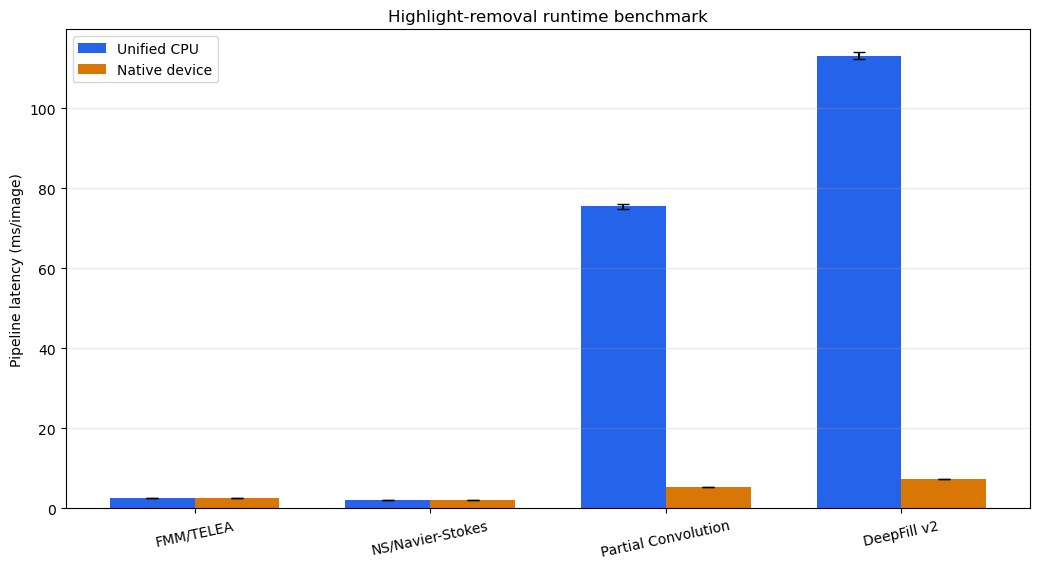

In [18]:
# ==================== 汇总与补充材料表格 ====================
def read_protocol(protocol):
    frames = []
    metadata = {}
    for run_index in range(1, RUNS + 1):
        for method in METHODS:
            task = make_task(protocol, run_index, method)
            path = Path(task["output"])
            if not path.is_file():
                raise FileNotFoundError(f"缺少正式结果：{path}")
            frames.append(validate_result(path, task, len(IMAGE_FILES)))
            metadata_path = Path(str(path) + ".metadata.json")
            metadata[task["key"]] = json.loads(
                metadata_path.read_text(encoding="utf-8")
            )
    return pd.concat(frames, ignore_index=True), metadata


def run_level_means(detail):
    return detail.groupby(
        ["protocol", "method", "run_index", "device_label"], as_index=False
    )[["pipeline_ms", "core_ms", "file_to_file_ms"]].mean()


def summarize(detail, protocol):
    summaries = []
    for method in METHODS:
        current = detail.loc[detail["method"] == method]
        if current["run_index"].nunique() != RUNS:
            raise RuntimeError(f"{method}缺少三次独立运行。")
        if current["image_name"].nunique() != len(IMAGE_FILES):
            raise RuntimeError(f"{method}的图像覆盖不完整。")
        if current["device_label"].nunique() != 1:
            raise RuntimeError(f"{method}在不同运行中使用了不同设备。")

        run_means = run_level_means(current)
        per_image = current.groupby("image_name")[[
            "pipeline_ms", "core_ms", "file_to_file_ms"
        ]].mean()
        pipeline_mean = float(run_means["pipeline_ms"].mean())
        summaries.append({
            "protocol": protocol,
            "Protocol": PROTOCOL_LABELS[protocol],
            "method": method,
            "Method": METHOD_LABELS[method],
            "Device": current["device_label"].iloc[0],
            "Restoration input": f"{RESTORE_WIDTH} × {RESTORE_HEIGHT}",
            "Restoration output": f"{RESTORE_WIDTH} × {RESTORE_HEIGHT}",
            "Final output": f"{OUTPUT_WIDTH} × {OUTPUT_HEIGHT}",
            "Images": int(current["image_name"].nunique()),
            "Runs": int(current["run_index"].nunique()),
            "pipeline_mean": pipeline_mean,
            "pipeline_sd": float(run_means["pipeline_ms"].std(ddof=1)),
            "core_mean": float(run_means["core_ms"].mean()),
            "core_sd": float(run_means["core_ms"].std(ddof=1)),
            "file_mean": float(run_means["file_to_file_ms"].mean()),
            "file_sd": float(run_means["file_to_file_ms"].std(ddof=1)),
            "median": float(per_image["pipeline_ms"].median()),
            "p95": float(np.percentile(per_image["pipeline_ms"], 95)),
            "fps": 1000.0 / pipeline_mean,
        })

    summary = pd.DataFrame(summaries)
    fmm_mean = float(
        summary.loc[summary["method"] == "fmm", "pipeline_mean"].iloc[0]
    )
    summary["speedup"] = fmm_mean / summary["pipeline_mean"]
    return summary


def paper_table(summary):
    return pd.DataFrame({
        "Protocol": summary["Protocol"],
        "Method": summary["Method"],
        "Device": summary["Device"],
        "Restoration input": summary["Restoration input"],
        "Restoration output": summary["Restoration output"],
        "Final output": summary["Final output"],
        "Images": summary["Images"],
        "Runs": summary["Runs"],
        "Pipeline Mean ± SD (ms)": [
            f"{mean:.4f} ± {sd:.4f}"
            for mean, sd in zip(summary["pipeline_mean"], summary["pipeline_sd"])
        ],
        "Core Mean ± SD (ms)": [
            f"{mean:.4f} ± {sd:.4f}"
            for mean, sd in zip(summary["core_mean"], summary["core_sd"])
        ],
        "File-to-file Mean ± SD (ms)": [
            f"{mean:.4f} ± {sd:.4f}"
            for mean, sd in zip(summary["file_mean"], summary["file_sd"])
        ],
        "Median (ms)": summary["median"].map(lambda value: f"{value:.4f}"),
        "P95 (ms)": summary["p95"].map(lambda value: f"{value:.4f}"),
        "FPS": summary["fps"].map(lambda value: f"{value:.4f}"),
        "Speedup vs FMM": summary["speedup"].map(lambda value: f"{value:.4f}"),
    })


SUPPLEMENTARY_TABLE_NOTE = (
    "Note: All methods used the same 384 × 256 restoration input and "
    "pixel-identical 99.5th-percentile highlight mask, and produced a "
    "384 × 256 restoration output; outputs were resized to 384 × 288 "
    "for downstream segmentation. Values are mean ± SD across three "
    "independent full-dataset runs (2,987 images); Median and P95 were "
    "computed after averaging per-image latency across runs. Model loading "
    "and 30 warm-up images were excluded. Pipeline latency excludes disk "
    "I/O, whereas file-to-file latency includes image decoding, lossless "
    "intermediate mask I/O for FMM/NS, and identical lossless PNG output "
    "encoding for all methods. In the "
    "native-device protocol, speedup versus FMM compares CPU and GPU "
    "deployment and is not a same-hardware algorithmic speedup."
)


if RUN_MODE == "report":
    fair_detail, fair_metadata = read_protocol("fair_cpu_common")
    native_detail, native_metadata = read_protocol("native_device_pipeline")
    expected = len(IMAGE_FILES) * RUNS * len(METHODS)
    if len(fair_detail) != expected or len(native_detail) != expected:
        raise RuntimeError("正式结果总行数错误。")

    all_detail = pd.concat([fair_detail, native_detail], ignore_index=True)
    validate_shared_masks(all_detail)

    fair_summary = summarize(fair_detail, "fair_cpu_common")
    native_summary = summarize(native_detail, "native_device_pipeline")
    combined_summary = pd.concat(
        [fair_summary, native_summary], ignore_index=True
    )
    supplementary_table = paper_table(combined_summary)

    fair_detail.to_csv(
        OUTPUT_DIR / "runtime_fair_cpu_per_image.csv", index=False
    )
    native_detail.to_csv(
        OUTPUT_DIR / "runtime_native_per_image.csv", index=False
    )
    run_summary = pd.concat([
        run_level_means(fair_detail), run_level_means(native_detail)
    ], ignore_index=True)
    run_summary.to_csv(
        OUTPUT_DIR / "runtime_run_level_means.csv", index=False
    )
    combined_summary.to_csv(
        OUTPUT_DIR / "runtime_supplementary_summary_numeric.csv", index=False
    )
    supplementary_table.to_csv(
        OUTPUT_DIR / "runtime_supplementary_summary_table.csv", index=False
    )
    supplementary_table.to_csv(
        OUTPUT_DIR / "runtime_supplementary_summary_table.tsv",
        sep="\t", index=False,
    )
    (OUTPUT_DIR / "runtime_supplementary_table_note.txt").write_text(
        SUPPLEMENTARY_TABLE_NOTE, encoding="utf-8"
    )
    hardware_table = pd.DataFrame([
        {
            "Item": key,
            "Value": json.dumps(value, ensure_ascii=False)
            if isinstance(value, (dict, list)) else value,
        }
        for key, value in environment.items()
    ])

    with pd.ExcelWriter(
        OUTPUT_DIR / "runtime_supplementary_summary_table.xlsx"
    ) as writer:
        supplementary_table.to_excel(
            writer, sheet_name="Supplementary_Table", index=False
        )
        combined_summary.to_excel(
            writer, sheet_name="Numeric_Results", index=False
        )
        run_summary.to_excel(writer, sheet_name="Run_Level", index=False)
        pd.DataFrame({"Table note": [SUPPLEMENTARY_TABLE_NOTE]}).to_excel(
            writer, sheet_name="Notes", index=False
        )
        hardware_table.to_excel(writer, sheet_name="Hardware", index=False)

    environment["worker_runs"] = {**fair_metadata, **native_metadata}
    write_json(OUTPUT_DIR / "runtime_hardware_environment.json", environment)

    print("\n补充材料汇总表：四种高光修复方法的运行时间")
    display(supplementary_table)
    print("\n" + SUPPLEMENTARY_TABLE_NOTE)

    fair_plot = fair_summary.set_index("method").reindex(METHODS)
    native_plot = native_summary.set_index("method").reindex(METHODS)
    positions = np.arange(len(METHODS))
    width = 0.36
    figure, axis = plt.subplots(figsize=(10.5, 5.8))
    axis.bar(
        positions - width / 2, fair_plot["pipeline_mean"], width,
        yerr=fair_plot["pipeline_sd"], capsize=4, label="Unified CPU",
        color="#2563EB",
    )
    axis.bar(
        positions + width / 2, native_plot["pipeline_mean"], width,
        yerr=native_plot["pipeline_sd"], capsize=4, label="Native device",
        color="#D97706",
    )
    axis.set_xticks(positions)
    axis.set_xticklabels([METHOD_LABELS[m] for m in METHODS], rotation=12)
    axis.set_ylabel("Pipeline latency (ms/image)")
    axis.set_title("Highlight-removal runtime benchmark")
    axis.legend()
    axis.grid(axis="y", alpha=0.25)
    figure.tight_layout()
    figure.savefig(
        FIGURE_DIR / "runtime_supplementary_comparison.png",
        dpi=300, bbox_inches="tight",
    )
    plt.show()
